# Q-learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/05-reinforcement/q-learning/q-learning-notebook.ipynb)

Companion notebook for the *Q-learning* slides. Each idea is written first by hand with NumPy
and then checked with an independent computation that should give the same answer.

**Data:** no data set; the agent moves in the 4 × 3 grid world (wall at (2, 2), goal +1, pit −1, each move −0.04), here without slipping.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

RANDOM_STATE = 42
GAMMA = 0.9
ALPHA = 0.5
EPSILON = 0.2
EPISODES = 3000
rng = np.random.default_rng(RANDOM_STATE)

CELLS = [(x, y) for y in range(3) for x in range(4) if (x, y) != (1, 1)]  # (column, row), 0-based
MOVES = [(0, 1), (1, 0), (0, -1), (-1, 0)]  # up, right, down, left
GOAL, PIT = CELLS.index((3, 2)), CELLS.index((3, 1))
N_STATES, N_ACTIONS = len(CELLS), len(MOVES)


def step(s, a):
    """The environment: return (reward, next state, done). The agent never sees inside."""
    cell = (CELLS[s][0] + MOVES[a][0], CELLS[s][1] + MOVES[a][1])
    s_next = CELLS.index(cell) if cell in CELLS else s
    reward = {GOAL: 1.0, PIT: -1.0}.get(s_next, -0.04)
    return reward, s_next, s_next in (GOAL, PIT)

## 1. Learning in small steps

A running mean $\bar{x}_n = \bar{x}_{n-1} + \frac{1}{n}(x_n - \bar{x}_{n-1})$ never stores the old numbers,
yet ends at the ordinary mean.

In [2]:
numbers = rng.normal(5, 2, size=1000)
mean = 0.0
for n, x in enumerate(numbers, start=1):
    mean += (x - mean) / n

print(f"running mean {mean:.4f} | same result:", np.isclose(mean, np.mean(numbers)))

running mean 4.9422 | same result: True


## 2. The Q-learning update

Target $y = r + \gamma \max_{a'} Q(s', a')$, TD error $\delta = y - Q(s, a)$, update $Q(s, a) \leftarrow Q(s, a) + \alpha\,\delta$.
The deck's example: moving a fraction $\alpha$ toward the target is the same as the blend $(1 - \alpha)\,Q + \alpha\, y$.

In [3]:
q_old, r, max_next, alpha = 0.5, 0.0, 0.8, 0.1
target = r + GAMMA * max_next
delta = target - q_old
q_new = q_old + alpha * delta

print(f"y = {target:.2f}, delta = {delta:.2f}, new Q = {q_new:.3f}")
print("same result:", np.isclose(q_new, (1 - alpha) * q_old + alpha * target))

y = 0.72, delta = 0.22, new Q = 0.522
same result: True


## 3. ε-greedy exploration

With chance $\varepsilon$ take a random action, otherwise the greedy one, so the greedy action has chance
$1 - \varepsilon + \varepsilon/|\mathcal{A}|$ and each other action $\varepsilon/|\mathcal{A}|$.
Many sampled choices should match these chances (up to sampling noise).

In [4]:
def epsilon_greedy(q_row, epsilon):
    return rng.integers(len(q_row)) if rng.random() < epsilon else int(np.argmax(q_row))


q_row = np.array([0.66, 0.71, 0.55, 0.60])
chances = np.full(N_ACTIONS, EPSILON / N_ACTIONS)
chances[np.argmax(q_row)] += 1 - EPSILON

choices = [epsilon_greedy(q_row, EPSILON) for _ in range(20_000)]
print("formula:", chances, "| same result:", np.allclose(np.bincount(choices) / len(choices), chances, atol=0.01))

formula: [0.05 0.85 0.05 0.05] | same result: True


## 4. Q-learning on the grid

For reference, value iteration with the model (Topic 20) gives the exact $Q^*$. The learner below never uses it:
it only sees tuples $(s, a, r, s')$ and updates one entry per step, with terminal states worth 0.
Each episode starts in a random cell so that every pair keeps being tried.

In [5]:
non_terminal = [s for s in range(N_STATES) if s not in (GOAL, PIT)]
Q_star = np.zeros((N_STATES, N_ACTIONS))
for _ in range(200):
    for s in non_terminal:
        for a in range(N_ACTIONS):
            r, s_next, done = step(s, a)
            Q_star[s, a] = r if done else r + GAMMA * Q_star[s_next].max()

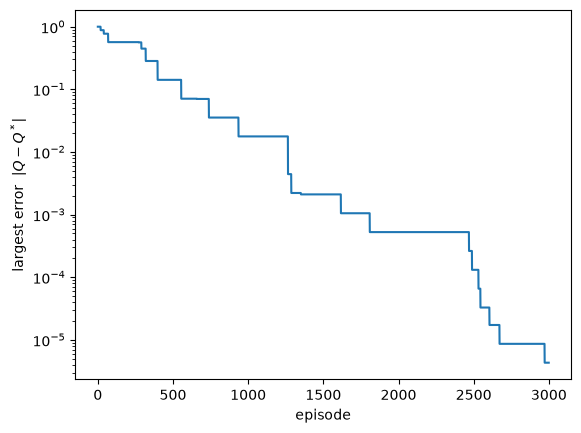

In [6]:
Q = np.zeros((N_STATES, N_ACTIONS))
errors = []
for _ in range(EPISODES):
    s, done = rng.choice(non_terminal), False
    while not done:
        a = epsilon_greedy(Q[s], EPSILON)
        r, s_next, done = step(s, a)
        target = r if done else r + GAMMA * Q[s_next].max()
        Q[s, a] += ALPHA * (target - Q[s, a])
        s = s_next
    errors.append(np.abs(Q - Q_star).max())

plt.semilogy(errors)
plt.xlabel("episode")
plt.ylabel("largest error  $|Q - Q^*|$")
plt.show()

Learned values are approximate, so we compare them with a small tolerance, and we check that the greedy
action is optimal in every cell (when two actions tie, either one counts).

In [7]:
greedy = Q[non_terminal].argmax(axis=1)
print("same values:", np.allclose(Q[non_terminal], Q_star[non_terminal], atol=0.01))
print("greedy policy is optimal:", np.allclose(Q_star[non_terminal, greedy], Q_star[non_terminal].max(axis=1)))

same values: True
greedy policy is optimal: True


## Exercises

1. Set `EPSILON = 0` and start every episode in cell (1, 1). Which entries of `Q` stay at 0?
2. Replace the target by SARSA's $r + \gamma\, Q(s', a')$, with $a'$ the action really taken next, and compare the greedy policies.
3. Try `ALPHA = 0.05` and `ALPHA = 1`. How does the error curve of section 4 change?